<div align="left">
<img src="https://licensebuttons.net/l/by-nc-sa/3.0/88x31.png" align="right">
<p align="left"><b>Autor: Víctor Sánchez Anguix</b></p>
</div>
<img align="left" width="30%" src="https://www.upv.es/entidades/etsinf/wp-content/uploads/2024/06/logo_etsinf_valenciano_grisUPV.svg"/> <img width="30%" src="https://www.upv.es/perfiles/pas-pdi/imagenes/marca_UPV_principal_negro150.png" align="right"/>


# Optimization: Laboratory 3 - Automating the construction of MILP models

Linear Programming (LP) and Mixed Integer Linear Programming (MILP) are two popular types of mathematical optimization models that can be applied to a range of scenarios such as transportation, logistics, economics, engineering, and so forth.

Part of their popularity is explainable due to existence of efficient algorithms for solving such problems. In particular, LP problems can be efficiently solved by means of the Simplex algorithm and its variants. Modern solvers can solve LP problems with thousands and millions of variables in an affordable time. MILP problems can be solved by means of alternative strategies such as branch-and-bound, branch-and-price, and branch-and-cut algorithms. These algorithms are a bit less efficient than the Simplex algorithm (in fact, some of them internally solve many LP problems with the Simplex algorithm) but the state-of-the-art solvers can still solve large problems in a reasonable time. Despite their apparent simplicity, these models can be applied to a vast range of domains and problems, and they are even able to solve apparently non-linear scenarios with the use of binary decision variables.

## Learning outcomes
* Declare integer and boolean decision variables using ORTools.
* Using looping and data structures to automatize the programming of large optimization models.
* Identify the most appropriate data structure for storing decision variables and constraints for large optimization models.


In [3]:
!pip install ortools

## Solving simple Integer Linear Programming Models

As you may have studied in the lectures, many models also involve integer and binary decision variables. In fact, the reality is that many models include a mix of real, integer, and binary variables.

In reality, there are just a few changes to introduce when one programs models with integer or binary variables. The first change to be introduced corresponds to the solver. GLOP only solves models solely formed by real-valued variables. Therefore, we need to change the solver when initializing the *Solver* object. There are some free alternatives already implemented in ORTools such as *SCIP* and *CBC*. The following block of code shows how two initialize both types of solvers.

```python
solver = pywraplp.Solver.CreateSolver("SCIP") # Example, creating a SCIP solver
solver2 = pywraplp.Solver.CreateSolver("CBC") # Example, creating a CBC solver
solver2 = pywraplp.Solver.CreateSolver("Highs") # Example, creating a Highs solver
```

The other change is introduced when creating decision variables as, somehow, we need to specify that we want to create an integer or a binary variable. The changes are not drastic, and it follows a very similar structure to the one employed for creating continuous variables. The next code snippet creates an integer decision variable ($X\geq 0$) and a binary variable.

```python
X1 = solver.IntVar(0, solver.infinity(), "Example of an integer variable creation")
X2 = solver.BoolVar("Example of a binary variable creation")
```

Please, realize that binary variables do not need to specify lower and upper bounds, as the bounds are always 0 and 1 respectively.

Next, we show an example of how to solve a scenario that solely involves binary variables. It is a variant of the knapsack problem.

>*A shipping company should transport goods to the other side of the ocean. For that task, the company has a cargo ship that has a cargo space of 500 m2 and a maximum cargo weight of 3,000 Kg. The next table shows the weight, area covered, and profit generated by shipping different types of goods. Determine the optimal cargo for the ship*

|Goods | Weight (Kg) | Space (m2) | Profit (€) |
| ---  |   ---       |   ---      |    ---     |
| Furniture | 590 | 125 | 1200 |
| Electronics | 1150 | 210 | 2800 |
| Fragile goods | 800 | 100 | 1900 |
| Gold | 1200 | 188 | 3000 |
| Gas | 2100 | 200 | 2900 |

The model associated to this scenario is the following:

$max \;\; Z: 1200 X_1 + 2800 X_2 + 1900 X_3 + 3000 X_4 + 2900 X_5$

subject to:

weight: $590 X_1 + 1150 X_2 + 800 X_3 + 1200 X_4 + 2100 X_5 \leq 3000$

space: $125 X_1 + 210 X_2 + 100 X_3 + 188 X_4 + 200 X_5 \leq 500$

with:

$X_i: $ 1 if the company loads good $i$ into the cargo ship, 0 otherwise; $X_i \in \{0,1\}, i=1\dots 5$

The following code snippet shows the code in ORTools that solves the associated optimization problem.

In [4]:
from ortools.linear_solver import pywraplp
from numpy import average, std
solver = pywraplp.Solver.CreateSolver("SCIP") #We create a solver that supports binary variables

#Creation of decision variables
X1 = solver.BoolVar("Do we load the furniture?")
X2 = solver.BoolVar("Do we load electronics?")
X3 = solver.BoolVar("Do we load fragile goods?")
X4 = solver.BoolVar("Do we load gold?")
X5 = solver.BoolVar("Do we load the gas?")

#Create weight constraint
c_weight = solver.Constraint(-solver.infinity(), 3000)
c_weight.SetCoefficient(X1, 590)
c_weight.SetCoefficient(X2, 1150)
c_weight.SetCoefficient(X3, 800)
c_weight.SetCoefficient(X4, 1200)
c_weight.SetCoefficient(X5, 2100)

#Create space constraint
c_space = solver.Constraint(-solver.infinity(), 500)
c_space.SetCoefficient(X1, 125)
c_space.SetCoefficient(X2, 1150)
c_space.SetCoefficient(X3, 100)
c_space.SetCoefficient(X4, 188)
c_space.SetCoefficient(X5, 200)

#Create objective function
objective = solver.Objective()
objective.SetMaximization()
objective.SetCoefficient(X1, 1200)
objective.SetCoefficient(X2, 2800)
objective.SetCoefficient(X3, 1900)
objective.SetCoefficient(X4, 3000)
objective.SetCoefficient(X5, 2900)

result = solver.Solve()


if result == solver.ABNORMAL :
  print("Execution finished by an error")
elif result == solver.FEASIBLE :
  print("In the specified time limit the solver has found a feasible solution")
  print(X1.name(), X1.solution_value())
  print(X2.name(), X2.solution_value())
  print(X3.name(), X3.solution_value())
  print(X4.name(), X4.solution_value())
  print(X5.name(), X5.solution_value())
  print("The optimal value for the objective function is", objective.Value())
elif result == solver.INFEASIBLE :
  print("There is no feasible solution for the problem")
elif result == solver.NOT_SOLVED :
  print("In the specified time limit the solver has not found any feasible solution")
elif result == solver.OPTIMAL :
  print("In the specified time limit the solver has found a feasible solution")
  print(X1.name(), X1.solution_value())
  print(X2.name(), X2.solution_value())
  print(X3.name(), X3.solution_value())
  print(X4.name(), X4.solution_value())
  print(X5.name(), X5.solution_value())
  print("The optimal value for the objective function is", objective.Value())
elif result == solver.UNBOUNDED :
  print("The solution is unbounded")
else :
  print("Unknown error code")


In the specified time limit the solver has found a feasible solution
Do we load the furniture? 1.0
Do we load electronics? 0.0
Do we load fragile goods? 1.0
Do we load gold? 1.0
Do we load the gas? 0.0
The optimal value for the objective function is 6100.0


## Task 1: Modeling and implementing a simple ILP problem

Again, it is time to test what we have learned so far. Let us try to model and obtain the solution for the following optimization scenario in ORTools. The scenario is defined as follows.

- - -
*A R&D company is going to plan its research activity for the next 5 years. At this moment, the company is going to decide on what research projects it is going to invest. The company has a total of 20 researchers that can be allocated to a single research project, and it has a budget of 70k € euros to invest. In addition to this, there are three labs (A, B, C) that can be allocated to projects. A lab can be used at most by two projects. The following table briefly states the needs and profit generated by each of the projects:*

| Project | Researchers | Investment | Labs | Profit |
|  ---    |    ---      |    ---     |  --  |  ---   |
| Nanochips | 10 | 35k | A, B | 60k |
| VR  |   8 | 15k | C | 80k |
| Cybersecurity | 3 | 20k | A, C | 29k |
| Sustainability | 6 | 10k | A, B, C | 12k |
| Smart manufacturing | 9 | 30k | B, C | 70k |
| IoT | 8 | 20k | B | 50k |

*On what projects should the company invest? What is the expected profit?*
- - -

Now, you should define the Linear programming model for this scenario, as well as obtaining the optimal solution employing ORTools. Start by defining the model on paper, and then attempt to program the solution in Python. Create the following Python variables as decision variables for each project: *x1*, *x2*, *x3*, *x4*, *x5*, and *x6*. Store the objective function into an object named as *objective*.

In [5]:
#Your code here

## Automatizing the construction of large optimization models

So far, all of the models that we have solved were relatively small, and they could be programmed by explicitly writing an instruction for each step. However, when we have hundreds or thousands of variables and/or constraints, it is an impossible task to be carried out by hand. In those situations, we need to automate the model so that many variables and constraints are created. Do we know any programming structure to repeat instructions many times? Exactly, we are going to need looping structures.

Many people struggle to identify when looping structures are needed. Fortunately, there are some simple rules that we can employ to translate optimization models into pseudo-code and that will work for many scenarios. Let us assume that we have the classic transportation model.

$min \;\; Z: \overset{m}{\underset{i=1}{\sum}} \overset{n}{\underset{j=1}{\sum}} c_{i,j} \times X_{i,j}$

subject to:

$origin_i: \overset{n}{\underset{j=1}{\sum}} X_{i,j} \leq s_i \; ; \;  i=1\dots m$

$destination_j: \overset{m}{\underset{i=1}{\sum}} X_{i,j} \geq d_j \; ; \;  j=1\dots n$

with:

$X_{i,j}:$ Units of product transported between origin $i$ and destination $j$; \; $X_{i,j} \geq 0$;  $X_{i,j} \in \mathbb{R}; i=1 \dots m; j=1 \dots n$

$c_{i,j}:$ Unitary transportation cost between origin $i$ and destination $j$;   $i=1 \dots m; j=1 \dots n$;

$s_i$: Product availability at origin $i$; $i=1 \dots m $

$d_j$: Minimum demand at destination $j$; $j=1 \dots n$

The first question that one should ask oneself is, how many decision variables do I need to create? We can find the answer to that question in the following part of the model.

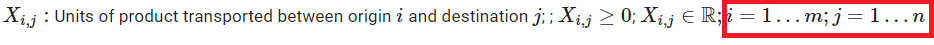

As suggested by the model, there should be a variable for each combination of prospective values for $i$ and $j$. That is, a total of $m\times n$ variables. How can we automate the creation of those variables, one for each combination of $i$ and $j$? In this case, this can be accomplished with two for loops. The code in Python would be similar to the following:

```
FOR i from 1 to m:
    FOR j from 1 to n:
        CREATE AND STORE VARIABLE
```

The next step involves creating the objective function, for instance. This is simple, there is a single objective function. So the instruction to create the objective function should be called exactly once. However, there are many variables in the objective function whose coefficients need to be adjusted. Which ones? The ones pointed out by the objective function:

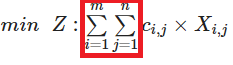

That is, we need to adjust the coefficient for every variable $X_{i,j}$, for every combination of values of $i$ and $j$. Therefore, we need to set the coefficient for $m\dots n$ variables. Similarly, we can automate the creation of the objective function in Python following this pseudocode:

```
CREATE OBJECTIVE FUNCTION
FOR i from 1 to m:
   FOR j FROM 1 to n:
       RETRIEVE VARIABLE X_ij
       RETRIEVE COEFFICIENT X_ij
       SET COEFFICIENT FOR X_ij IN OBJECTIVE FUNCTION
```

Of course, how the variables and the coefficients are retrieved depends on what data structure you used to store variables (i.e., lists, dictionaries, etc.) and where input parameters are stored (e.g., database, list, dictionary, etc.).

Let us proceed with the next part of the model, in this case the constraints. Let us focus on the $origin_i$ definition. The first question you should ask yourself is, how many constraints of this type do I need? You can find that information in the following part of the model.

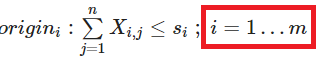

You need exactly $m$ constraints. Therefore, the code to create this constraint will be repeated $m$ times. Repetition? It looks like time for a looping structure.

```
FOR i from 1 to m:
   RETRIEVE LOWER AND UPPER BOUND
   CREATE EMPTY CONSTRAINT WITH LOWER AND UPPER BOUND
```

The next question you need to ask is, what variables should participate in the contraint definition? Again, the answer is in the constraint itself.

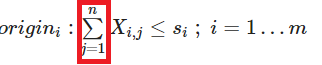

Given a specific origin $i$, the variables that participate in the constraint are every combination of the specific value of $i$ with all possible values of $j$. Therefore, we will need another looping structure for this task. The pseudocode above can be now completed.

```
FOR i from 1 to m:
   RETRIEVE LOWER AND UPPER BOUND
   CREATE EMPTY CONSTRAINT c WITH LOWER AND UPPER BOUND
   FOR j from 1 to n:
       RETRIEVE COEFFICIENT FOR X_ij
       RETRIEVE VARIABLE X_ij
       SET COEFFICIENT OF X_ij IN CONSTRAINT c
```

Excellent! We have automated the construction of the origin constraints. Following the same rationale, we can also produce the pseudocode for the destination constraints

```
FOR j from 1 to n:
   RETRIEVE LOWER AND UPPER BOUND
   CREATE EMPTY CONSTRAINT c WITH LOWER AND UPPER BOUND
   FOR i from 1 to m:
       RETRIEVE COEFFICIENT FOR X_ij
       RETRIEVE VARIABLE X_ij
       SET COEFFICIENT OF X_ij IN CONSTRAINT c
```


The following piece of code defines the input data for a transportation problem with 20 origins and 10 destinations. The *stock_at_origin* dictionary holds key-value pairs where the key is the origin index and the value is the product stock at that origin. The *demand_at_destination* dictionary holds key-value pairs where the key is the destination index and the value is the minimum product demand at that destination. The *transportation_cost_per_unit* is a dictionary that holds key-value pairs where the key is a tuple with two indices (origin index and destination index) and the value is the unitary cost of transporting a unit between that origin and destination.

In [6]:
number_origins = 20
number_destinations = 10

stock_at_origin = {
    0: 28,
    1: 77,
    2: 15,
    3: 55,
    4: 76,
    5: 51,
    6: 61,
    7: 10,
    8: 94,
    9: 31,
    10: 89,
    11: 63,
    12: 12,
    13: 91,
    14: 57,
    15: 41,
    16: 35,
    17: 47,
    18: 74,
    19: 57,
}

demand_at_destination = {
    0: 31,
    1: 381,
    2: 539,
    3: 15,
    4: 45,
    5: 10,
    6: 13,
    7: 10,
    8: 10,
    9: 10,
}

transportation_cost_per_unit = {
    (0, 0): 0.8,
    (0, 1): 0.84,
    (0, 2): 0.59,
    (0, 3): 0.21,
    (0, 4): 0.22,
    (0, 5): 0.44,
    (0, 6): 0.94,
    (0, 7): 0.03,
    (0, 8): 0.35,
    (0, 9): 0.47,
    (1, 0): 0.92,
    (1, 1): 0.44,
    (1, 2): 0.39,
    (1, 3): 0.62,
    (1, 4): 0.8,
    (1, 5): 0.38,
    (1, 6): 0.53,
    (1, 7): 0.09,
    (1, 8): 0.99,
    (1, 9): 0.11,
    (2, 0): 0.51,
    (2, 1): 0.06,
    (2, 2): 0.11,
    (2, 3): 0.35,
    (2, 4): 0.82,
    (2, 5): 0.05,
    (2, 6): 0.29,
    (2, 7): 0.68,
    (2, 8): 0.59,
    (2, 9): 0.26,
    (3, 0): 0.32,
    (3, 1): 0.16,
    (3, 2): 0.49,
    (3, 3): 0.13,
    (3, 4): 0.21,
    (3, 5): 0.86,
    (3, 6): 0.18,
    (3, 7): 0.68,
    (3, 8): 0.27,
    (3, 9): 0.45,
    (4, 0): 0.65,
    (4, 1): 0.1,
    (4, 2): 0.68,
    (4, 3): 0.82,
    (4, 4): 0.63,
    (4, 5): 0.3,
    (4, 6): 0.13,
    (4, 7): 0.35,
    (4, 8): 0.02,
    (4, 9): 0.86,
    (5, 0): 0.85,
    (5, 1): 0.91,
    (5, 2): 0.77,
    (5, 3): 0.94,
    (5, 4): 0.29,
    (5, 5): 0.47,
    (5, 6): 0.63,
    (5, 7): 0.99,
    (5, 8): 0.55,
    (5, 9): 0.76,
    (6, 0): 0.25,
    (6, 1): 0.47,
    (6, 2): 0.32,
    (6, 3): 0.81,
    (6, 4): 0.24,
    (6, 5): 0.33,
    (6, 6): 0.22,
    (6, 7): 0.18,
    (6, 8): 0.2,
    (6, 9): 0.61,
    (7, 0): 0.07,
    (7, 1): 0.44,
    (7, 2): 1.0,
    (7, 3): 0.45,
    (7, 4): 0.01,
    (7, 5): 0.52,
    (7, 6): 0.77,
    (7, 7): 0.87,
    (7, 8): 0.87,
    (7, 9): 0.37,
    (8, 0): 0.57,
    (8, 1): 0.53,
    (8, 2): 0.14,
    (8, 3): 0.38,
    (8, 4): 0.46,
    (8, 5): 0.36,
    (8, 6): 0.99,
    (8, 7): 0.58,
    (8, 8): 0.63,
    (8, 9): 0.02,
    (9, 0): 0.91,
    (9, 1): 0.58,
    (9, 2): 0.04,
    (9, 3): 0.91,
    (9, 4): 0.51,
    (9, 5): 0.21,
    (9, 6): 0.09,
    (9, 7): 0.61,
    (9, 8): 0.13,
    (9, 9): 0.68,
    (10, 0): 0.7,
    (10, 1): 0.83,
    (10, 2): 0.16,
    (10, 3): 0.93,
    (10, 4): 0.42,
    (10, 5): 0.89,
    (10, 6): 0.27,
    (10, 7): 0.24,
    (10, 8): 0.05,
    (10, 9): 0.91,
    (11, 0): 0.48,
    (11, 1): 0.31,
    (11, 2): 0.36,
    (11, 3): 0.67,
    (11, 4): 0.39,
    (11, 5): 0.87,
    (11, 6): 0.86,
    (11, 7): 0.3,
    (11, 8): 0.43,
    (11, 9): 0.27,
    (12, 0): 0.02,
    (12, 1): 0.43,
    (12, 2): 0.66,
    (12, 3): 0.59,
    (12, 4): 0.57,
    (12, 5): 0.59,
    (12, 6): 0.37,
    (12, 7): 0.65,
    (12, 8): 0.52,
    (12, 9): 0.64,
    (13, 0): 0.14,
    (13, 1): 0.43,
    (13, 2): 0.95,
    (13, 3): 0.15,
    (13, 4): 0.25,
    (13, 5): 0.18,
    (13, 6): 0.5,
    (13, 7): 0.86,
    (13, 8): 0.62,
    (13, 9): 0.79,
    (14, 0): 0.85,
    (14, 1): 0.08,
    (14, 2): 0.05,
    (14, 3): 0.37,
    (14, 4): 0.62,
    (14, 5): 0.63,
    (14, 6): 0.5,
    (14, 7): 0.43,
    (14, 8): 0.64,
    (14, 9): 0.42,
    (15, 0): 0.68,
    (15, 1): 0.5,
    (15, 2): 0.2,
    (15, 3): 0.08,
    (15, 4): 0.54,
    (15, 5): 0.06,
    (15, 6): 0.24,
    (15, 7): 0.22,
    (15, 8): 0.82,
    (15, 9): 0.23,
    (16, 0): 0.87,
    (16, 1): 0.61,
    (16, 2): 0.7,
    (16, 3): 0.35,
    (16, 4): 0.39,
    (16, 5): 0.24,
    (16, 6): 0.39,
    (16, 7): 0.02,
    (16, 8): 0.88,
    (16, 9): 0.65,
    (17, 0): 0.23,
    (17, 1): 0.26,
    (17, 2): 0.36,
    (17, 3): 0.94,
    (17, 4): 0.68,
    (17, 5): 0.34,
    (17, 6): 0.56,
    (17, 7): 0.17,
    (17, 8): 0.02,
    (17, 9): 0.67,
    (18, 0): 0.38,
    (18, 1): 0.45,
    (18, 2): 0.31,
    (18, 3): 0.16,
    (18, 4): 0.65,
    (18, 5): 0.41,
    (18, 6): 0.99,
    (18, 7): 0.9,
    (18, 8): 0.46,
    (18, 9): 0.97,
    (19, 0): 0.11,
    (19, 1): 0.03,
    (19, 2): 0.41,
    (19, 3): 0.91,
    (19, 4): 0.22,
    (19, 5): 0.06,
    (19, 6): 0.24,
    (19, 7): 0.27,
    (19, 8): 0.9,
    (19, 9): 0.55,
}

Now let us solve program the model in ORTools following the pseudocode specified in the paragraphs above. Let us the start by defining the decision variables.

```
FOR i from 1 to m:
    FOR j from 1 to n:
        CREATE AND STORE VARIABLE
```

In [7]:
solver = pywraplp.Solver.CreateSolver("GLOP")

variables = {}

for i in range(number_origins):
  for j in range(number_destinations):
    v = solver.NumVar(0, solver.infinity(), "Units transported between: " + str((i,j)))
    variables[(i,j)] = v

In this case, we define a dictionary where we will store decision variables indexed according to their subindices $i$ and $j$ (origin and destination). We define variables as continuous as we are solving a standard version of the transportation problem, for which there are guarantees that the optimal solution will be integer.

Next, let us focus on programming the objective function.

```
CREATE OBJECTIVE FUNCTION
FOR i from 1 to m:
   FOR j FROM 1 to n:
       RETRIEVE VARIABLE X_ij
       RETRIEVE COEFFICIENT X_ij
       SET COEFFICIENT FOR X_ij IN OBJECTIVE FUNCTION
```

In [8]:
objective = solver.Objective()
objective.SetMinimization()
for i in range(number_origins):
  for j in range(number_destinations):
    v = variables[(i,j)]
    cost = transportation_cost_per_unit[(i,j)]
    objective.SetCoefficient(v, cost)

Let us implement now the origin constraints. Remember that there is a constraint for each origin, in order to guarantee that no more than the available stock is transported from that origin.

```
FOR i from 1 to m:
   RETRIEVE LOWER AND UPPER BOUND
   CREATE EMPTY CONSTRAINT c WITH LOWER AND UPPER BOUND
   FOR j from 1 to n:
       RETRIEVE COEFFICIENT FOR X_ij
       RETRIEVE VARIABLE X_ij
       SET COEFFICIENT OF X_ij IN CONSTRAINT c
```

In [9]:
stock_constraints = []

for i in range(number_origins):
  stock = stock_at_origin[i]
  c = solver.Constraint(-solver.infinity(), stock)
  for j in range(number_destinations):
    v = variables[(i,j)]
    c.SetCoefficient(v, 1)
  stock_constraints.append(c)

As the reader may observe, we create a constraint for each origin and then we store it into a Python list for accessing the constraint in case that we need it in the future.

Finally, we define the last type of constraints: demand constraints. For each destination we need to guarantee that it receives at least a minimum demand. The pseudocode for this part is:


```
FOR j from 1 to n:
   RETRIEVE LOWER AND UPPER BOUND
   CREATE EMPTY CONSTRAINT c WITH LOWER AND UPPER BOUND
   FOR i from 1 to m:
       RETRIEVE COEFFICIENT FOR X_ij
       RETRIEVE VARIABLE X_ij
       SET COEFFICIENT OF X_ij IN CONSTRAINT c
```

In [10]:
demand_constraints = []

for j in range(number_destinations):
  min_demand = demand_at_destination[j]
  c = solver.Constraint(min_demand, solver.infinity())
  for i in range(number_origins):
    v = variables[(i,j)]
    c.SetCoefficient(v,1)
  demand_constraints.append(c)

The complete code for the model is:

In [11]:
solver = pywraplp.Solver.CreateSolver("GLOP")

variables = {}

for i in range(number_origins):
  for j in range(number_destinations):
    v = solver.NumVar(0, solver.infinity(), "Units transported between: " + str((i,j)))
    variables[(i,j)] = v

objective = solver.Objective()
objective.SetMinimization()
for i in range(number_origins):
  for j in range(number_destinations):
    v = variables[(i,j)]
    cost = transportation_cost_per_unit[(i,j)]
    objective.SetCoefficient(v, cost)

stock_constraints = []

for i in range(number_origins):
  stock = stock_at_origin[i]
  c = solver.Constraint(-solver.infinity(), stock)
  for j in range(number_destinations):
    v = variables[(i,j)]
    c.SetCoefficient(v, 1)
  stock_constraints.append(c)

demand_constraints = []

for j in range(number_destinations):
  min_demand = demand_at_destination[j]
  c = solver.Constraint(min_demand, solver.infinity())
  for i in range(number_origins):
    v = variables[(i,j)]
    c.SetCoefficient(v,1)
  demand_constraints.append(c)

result = solver.Solve()

if result == solver.ABNORMAL :
  print("Execution finished by an error")
elif result == solver.FEASIBLE :
  print("In the specified time limit the solver has found a feasible solution")
  for i in range(number_origins):
    for j in range(number_destinations):
      v = variables[(i,j)]
      if v.SolutionValue()>0:
        print(v, v.solution_value())
  print("The value for the objective function is", objective.Value())
elif result == solver.INFEASIBLE :
  print("There is no feasible solution for the problem")
elif result == solver.NOT_SOLVED :
  print("In the specified time limit the solver has not found any feasible solution")
elif result == solver.OPTIMAL :
  print("In the specified time limit the solver has found a feasible solution")
  for i in range(number_origins):
    for j in range(number_destinations):
      v = variables[(i,j)]
      if v.SolutionValue()>0:
        print(v, v.solution_value())
  print("The optimal value for the objective function is", objective.Value())
elif result == solver.UNBOUNDED :
  print("The solution is unbounded")
else :
  print("Unknown error code")

In the specified time limit the solver has found a feasible solution
Units transported between: (0, 2) 12.999999999999998
Units transported between: (0, 3) 15.0
Units transported between: (1, 2) 67.0
Units transported between: (1, 9) 10.0
Units transported between: (2, 1) 15.0
Units transported between: (3, 1) 55.0
Units transported between: (4, 1) 76.0
Units transported between: (5, 2) 5.9999999999999964
Units transported between: (5, 4) 45.0
Units transported between: (6, 2) 61.0
Units transported between: (7, 0) 10.0
Units transported between: (8, 2) 94.0
Units transported between: (9, 2) 31.0
Units transported between: (10, 2) 89.0
Units transported between: (11, 1) 57.00000000000003
Units transported between: (11, 2) 5.99999999999997
Units transported between: (12, 0) 12.0
Units transported between: (13, 0) 9.000000000000002
Units transported between: (13, 1) 82.0
Units transported between: (14, 2) 57.0
Units transported between: (15, 2) 41.0
Units transported between: (16, 1) 1.9

## Task 2: Automating the construction of a diet model

In this first task we are going to program an optimization model for the calculation of an optimal daily diet. In the examples we have seen in class only a few types of food and a few nutrients were considered. However, the real world is much more complex than this and we potentially have many types of foods as well as many daily nutrient requirements. Recall that in diet optimization models the following problem arises:
* We want to obtain a diet with minimum/optimal cost.
* We must ensure that this diet has some nutritional requirements to be balanced.

Recall the standard formulation of this type of problem:

$min\;Z=\underset{i}{\sum} c_i X_i$.

subject to:

$min\_nutrient_j: \underset{i}{\sum}n_{i,j} X_i \geq min_j$

$max\_nutrient_j: \underset{i}{\sum}n_{i,j} X_i \leq max_j$.

with:

$X_i:$ amount of food $i$ introduced into the diet. $X_i \geq 0, X_i \in \mathbb{R}$

where $c_i$ is the cost of food $i$ in the market, $X_i$ represents the amount to take of food $i$, $j$ represents a possible nutrient to consider for the diet, $n_{i,j}$ is the amount of nutrient $j$ contributed by one unit of food $i$, $min_i$ is the minimum daily required value of nutrient $i$, and $max_i$ is the maximum daily required value of nutrient $i$. Note that in some cases the nutrients may not have a daily minimum or maximum.

Based on this generic model, we will build our own daily diet planner. This planner could be extended and used, for example, as a value-added service for a supermarket, or even as a mobile app to help shoppers.

First of all, let's collect the data that we will work with in this task. We will have two data sources: a first source containing information about each of the foods, and a second data source containing the daily food requirements for a healthy diet. The following code snippet contains the necessary instructions to bring these data sources into Python objects.

In [12]:
import requests
r = requests.get('https://gitlab.com/drvicsana/cop-practicas-upv/-/raw/master/data/food.json')
food_db = list( r.json().values() )

r = requests.get('https://gitlab.com/drvicsana/cop-practicas-upv/-/raw/master/data/food_requirements.json')
food_requirements = r.json()

Now, let's analyze a little bit the data sources that we have brought to this Python notebook. Let's start by analyzing the information we have in the *food_requirements* object. This is a list of Python dictionaries, where each dictionary contains the information of a daily nutritional requirement. Let's see an example with some records from this data source:

```json
[
  {
    "nutrient_id": 1003,
    "nutrient_name": "Protein",
    "lb": 40,
    "ub": 70
  },
  {
    "nutrient_id": 1005,
    "nutrient_name": "Sugars, Total NLEA",
    "ub": 5
  },
  ...
]
```

Each record within this list, represented by a dictionary, can have **up to** four different fields/keys. Let's see what they mean:

|Field|Description|Type|
|---|---|---|
|*nutrient_id*| Identifier of the nutrient type | Integer |
| *nutrient_name* | Name of the nutrient | String |
| *lb* (lowerbound) | Minimum recommended amount of the nutrient | Decimal |
| *ub* (upperbound) | Maximum recommended amount of the nutrient | Decimal |

Note that there may be records that do not have *ub* or *lb* depending on whether the health authorities recommend only a minimum, a maximum, or that the nutrient is in a range.

The information collected in the *food_db* object is somewhat more complex. It is a list of records (where a record is a dictionary) that represent each of the foods available for designing the healthy menu. The following example shows some records that we can find inside this list:

```json
[
  {
    "food_id": 345891,
    "name": "Tutturosso Green 14.5oz Diced Tomatoes",
    "price": 3.36,
    "nutrients":[
      {
        "nutrient_id":1003,
        "nutrient_name": "Protein",
        "nutrient_units": "G",
        "amount": 0.83
      },
      ...
      {
        "nutrient_id": 1008,
        "nutrient_name": "Energy",
        "nutrient_units": "KCAL",
        "amount": 21.0
      }
    ]
  },
  {
    "food_id": 353462,
    "name": "OREO COOKIES CHOCOLATE CREME 1X18.400 OZ",
    "price": 6.58,
    "nutrients": [
      {
        "nutrient_id": 1004,
        "nutrient_name": "Total lipid (fat)",
        "nutrient_units": "G",
        "amount": 20.69
      },
      ...
      {
        "nutrient_id": 2000,
        "nutrient_name": "Sugars, total including NLEA",
        "nutrient_units": "G",
        "amount": 44.83
      }
    ]
  }
]
```

The example above shows two different registers. One representing a can of diced tomatoes, and one representing a box of cookies. In reality, the list contains hundreds of thousands of different products. Let us now look in a little more detail at what each of the fields within each food record means.

|Field|Description|Type|
|---|---|---|
|*food_id*| Identifier of the food | Integer |*food_id*| Identifier of the food |*food_id*| Whole |
| *name* | Food name |  String |
|  *price* | Price of the food |  Decimal |
|  *nutrients* | A list containing information about the nutrients provided by the food | List of objects |

As we can see, each food contains a list of nutrients provided by the food itself. This list in turn contains dictionaries describing the nutrients provided by each of the foods. More specifically, each dictionary contains the following information:

|Field|Description|Type|
|---|---|---|
|*nutrient_id*|Nutrient identifier|Integer|
|*nutrient_name*| Name of the nutrient| String|
|*nutrient_units*| Units in which the nutrient is measured | String |
|*amount*| Amount of the nutrient provided by the food | Decimal |

For example, the cookies provide 20.69 grams of fat and 44.83 grams of sugars, while the tomatoes provide 0.83 grams of protein and 21 kilocalories.

In order to familiarize yourself with each of these data sources, we propose the completion of these simple exercises.
* Display the **twentieth record** of the food data source. Remember that *food_db* is a Python list and that you can access items in a list by position/index.
* Displays the **name** of the fifth food item in the data source.
* Displays the **price** of the 100th food item in the data source.
* Displays the **nutrients** provided by the third food item in the data source.
* Displays the **name** of the last nutrient contributed by the second food in the data source.
* Displays the **name** of the fifth nutrient listed in the *food_requirements* nutrient requirements list. Remember that this list is also accessed by index.

In [13]:
#Your code here


### Solver creation

Now we will start with the programming of this model for the optimization of economical and nutritious diets. First of all, import *pywraplp* and create an instance of the *GLOP* solver as we have done in other practices. Then create a solver for solving the problem.

In [14]:
#Your code here


### Variables creation

Now we will create the variables of the problem. Remember that in the diet problem we have as many variables as food. These variables are of continuous type and are greater than or equal to zero. In order to create the variables of the problem, we will necessarily have to create a variable for each food found in our food data source. More specifically, we should follow a code similar to the following pseudo-code:

```
We create an empty list to store the created variables
For each food :
   We create a variable whose name is the name of the food itself.
   We add the variable to the created list
```

The above pseudo-code should give us a hint as to what kind of programming structures we will need. Notice that we store the created variables in a data collection. We do this so that later, a posteriori, we can analyze the value of each of the variables created.

**NOTE:** We recommend that if there is any error in your code, you re-run all the code of the model creation (including the creation of the solver). We can do that or call the *clear* method on the solver. We must do this because otherwise the solver will have variables/restrictions defined in the wrong code and this can cause problems.

In [15]:
#Your code here

### Objective function creation

In theory, we should have created a variable for each food in our data source. Now we will create the objective function of the problem. Remember that in the case of the diet problem, we want to minimize this function. Furthermore, in the objective function each decision variable is multiplied by the cost of the variable.

We will only have to create one objective function. However, the price of each of the foods is found in each of the records of our data source *food_db*. Therefore, to adjust the coefficient of each of the variables in the objective function we will have to go through the food data source again. From there we will extract the prices for each of them. The code to be produced would be similar to the following pseudo-code:

```
We create the objective function and configure the type of optimization.
For each food:
    We collect the price associated with the food.
    We retrieve the variable associated with the food (If you have used a list, variables and food occupy the same position in their respective lists).
    We set the coefficient of the variable in the objective function to be the price
```

Again, the above pseudo-code should suggest the type of programming structures and instructions to use.

In [16]:
#Your code here

### Constraints creation

We have created both the decision variables and the objective function. It remains to define the problem constraints. In this case, the problem constraints determine the minimum and/or maximum amount of nutrients (in some cases only minimum, others only maximum, and others minimum and maximum) to digest with the diet.

Note that Google OR Tools allows us, once a constraint is created, to establish both a lower bound or *lowerbound* (minimum) and an upper bound or *upperbound* (maximum) for that constraint. That is, the mathematical expression we create with the constraint will be bounded by these two values. We use infinity or -infinity when we do not want it to be bounded above or below, respectively. As a consequence, we only need to create one constraint for each of the nutrients we find in the list of food requirements.

Each of the restrictions created will have as a coefficient accompanying the decision variable the amount of the nutrient provided by the food. There will be foods that do not provide a certain type of nutrient, so it will not be necessary to adjust their coefficient in the constraint created. Therefore, the pseudocode to create the constraints will be as follows.

```
We create a list to store each of the constraints created.
For each food recommendation:
  We create a constraint with associated lower and upper dimensions.
  For each food:
    If the food provides the nutrient:
      We retrieve how much of the nutrient it provides
      Retrieve the variable associated with the food
      We adjust the coefficient of the variable in the constraint created.
  We add the constraint to the constraint collection
```



In [17]:
#Your code here

### Model resolution
We are now ready to solve the problem. Now solve it using the appropriate methods and making sure that the solution obtained is optimal.**AT THIS POINT, WE RECOMMEND THAT YOU RE-EXECUTE THE WHOLE MODEL DEFINITION. THIS IS TO AVOID THE DEFINITION OF REPEATED VARIABLES, CONSTRAINTS, AND RESIDUALS FROM PREVIOUS RUNS**.

In [18]:
#Your code here

Having solved the problem, we would like to obtain both the cost of the optimal diet and the amounts of food in that diet. Develop code to obtain this information. **NOTE: The obtained diet is not realistic, since food restrictions are missing and prices have been generated in a pseudo-random way. It is simply an example for working with external data sources and automating the construction of a model**.

## Task 3: Automating the construction of a purchases model

In this case you will have to program a mathematical optimization model by automating the construction of the model. Therefore, you must take into account the following aspects:

* You will have to employ programming structures to automate the creation of the model, regardless of its size and particularities of the given data set.
* The model should be prepared for any input

The following is the statement of the exercise to be solved.

**INSTRUCTIONS**

A medical machinery manufacturing company must fill an urgent order at the lowest possible cost. In order to start the manufacturing process, it must ask its suppliers to manufacture parts that are then used in the manufacture of medical machinery. There are a total of $n$ suppliers and $m$ types of parts to be ordered. The ordering of a part type $j$ from a supplier $i$ has an associated cost $c_{i,j}$. In addition, ordering a part type $j$ from a supplier $i$ has an associated manufacturing time of $t_{i,j}$. $T$ is the maximum time in which we wish to receive the order. In addition, $d_{i,j}$ is the expected lifetime (in years) of part type $j$ ordered from supplier $i$. $M_i$ represents the maximum number of orders we can place with supplier $i$. $E$ represents the expected average lifetime of the manufactured machines. The model to be programmed is the following:

$min \;Z:\; \overset{n}{\underset{i=1}{\sum}} \overset{m}{\underset{j=1}{\sum}} c_{i,j} \times X_{i,j}$

subject to:

\[One order per part $j$\]: $\overset{n}{\underset{i=1}{\sum}} X_{i,j} = 1;\; j=1\dots m$

\[Total time orders\]: $\overset{m}{\underset{j=1}{\sum}} t_{i,j} \times X_{i,j} \leq T;\; i=1\dots n$

\[Average lifetime\]:  $ \frac{1}{m} \overset{n}{\underset{i=1}{\sum}} \overset{m}{\underset{j=1}{\sum}} d_{i,j} \times X_{i,j} \geq E $

\[Provider $i$ supplies any order\]: $\overset{m}{\underset{j=1}{\sum}} X_{i,j} \leq M_i Y_i;\; i=1\dots n $

\[Maximum number of providers\]: $\overset{n}{\underset{i=1}{\sum}} Y_i \leq 5;\;$

with:

$X_{i,j}:$ 1 if we order part $j$ to provider $i$, 0 otherwise. $X_{i,j} \in \{0,1\}, \; i=1\dots n, \; j=1\dots m$

$Y_i:$ 1 if we make an order to provider $i$, 0 otherwise. $Y_i \in \{0,1\}, \; i=1 \dots n$

Data has been loaded from a database in JSON format related to the possible suppliers. This information has been stored in the *providers_db* collection.


In [19]:
proveedores_bd = [
  {
    "id_proveedor": 0,
    "pedidos_maximos": 3,
    "pais": "GE",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 3,
        "coste_pedido": 4232.28,
        "tiempo_vida": 2.74
      },
      {
        "id_pieza": 1,
        "familia": "B",
        "tiempo_pedido": 4,
        "coste_pedido": 1806.13,
        "tiempo_vida": 3.25
      },
      {
        "id_pieza": 2,
        "familia": "B",
        "tiempo_pedido": 5,
        "coste_pedido": 3266.52,
        "tiempo_vida": 7.01
      },
      {
        "id_pieza": 3,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 5436.54,
        "tiempo_vida": 5.44
      },
      {
        "id_pieza": 4,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 5826.7,
        "tiempo_vida": 7.16
      }
    ]
  },
  {
    "id_proveedor": 1,
    "pedidos_maximos": 1,
    "pais": "USA",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 5411.91,
        "tiempo_vida": 2.9
      },
      {
        "id_pieza": 1,
        "familia": "B",
        "tiempo_pedido": 4,
        "coste_pedido": 3610.4,
        "tiempo_vida": 6.81
      },
      {
        "id_pieza": 2,
        "familia": "C",
        "tiempo_pedido": 4,
        "coste_pedido": 6831.1,
        "tiempo_vida": 1.58
      },
      {
        "id_pieza": 3,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 2755.16,
        "tiempo_vida": 2.22
      },
      {
        "id_pieza": 4,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 3216.35,
        "tiempo_vida": 1.73
      }
    ]
  },
  {
    "id_proveedor": 2,
    "pedidos_maximos": 1,
    "pais": "ESP",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 5879.16,
        "tiempo_vida": 7.06
      },
      {
        "id_pieza": 1,
        "familia": "C",
        "tiempo_pedido": 4,
        "coste_pedido": 6338.86,
        "tiempo_vida": 5.35
      },
      {
        "id_pieza": 2,
        "familia": "A",
        "tiempo_pedido": 1,
        "coste_pedido": 6453.93,
        "tiempo_vida": 9.03
      },
      {
        "id_pieza": 3,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 3310.71,
        "tiempo_vida": 1.43
      },
      {
        "id_pieza": 4,
        "familia": "A",
        "tiempo_pedido": 1,
        "coste_pedido": 2991.95,
        "tiempo_vida": 7.93
      }
    ]
  },
  {
    "id_proveedor": 3,
    "pedidos_maximos": 3,
    "pais": "FR",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "B",
        "tiempo_pedido": 4,
        "coste_pedido": 5081.62,
        "tiempo_vida": 2.05
      },
      {
        "id_pieza": 1,
        "familia": "A",
        "tiempo_pedido": 2,
        "coste_pedido": 4344.84,
        "tiempo_vida": 1.42
      },
      {
        "id_pieza": 2,
        "familia": "A",
        "tiempo_pedido": 3,
        "coste_pedido": 7202.08,
        "tiempo_vida": 4.94
      },
      {
        "id_pieza": 3,
        "familia": "A",
        "tiempo_pedido": 2,
        "coste_pedido": 2934.84,
        "tiempo_vida": 2.97
      },
      {
        "id_pieza": 4,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 1868.8,
        "tiempo_vida": 5.04
      }
    ]
  },
  {
    "id_proveedor": 4,
    "pedidos_maximos": 5,
    "pais": "CH",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 1870.3,
        "tiempo_vida": 6.93
      },
      {
        "id_pieza": 1,
        "familia": "A",
        "tiempo_pedido": 1,
        "coste_pedido": 5322.37,
        "tiempo_vida": 9.59
      },
      {
        "id_pieza": 2,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 6207,
        "tiempo_vida": 5.45
      },
      {
        "id_pieza": 3,
        "familia": "A",
        "tiempo_pedido": 5,
        "coste_pedido": 2399.11,
        "tiempo_vida": 4.33
      },
      {
        "id_pieza": 4,
        "familia": "B",
        "tiempo_pedido": 5,
        "coste_pedido": 6584.98,
        "tiempo_vida": 9.82
      }
    ]
  },
  {
    "id_proveedor": 5,
    "pedidos_maximos": 1,
    "pais": "GE",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 6207.64,
        "tiempo_vida": 6.05
      },
      {
        "id_pieza": 1,
        "familia": "B",
        "tiempo_pedido": 5,
        "coste_pedido": 2987.68,
        "tiempo_vida": 2.67
      },
      {
        "id_pieza": 2,
        "familia": "A",
        "tiempo_pedido": 1,
        "coste_pedido": 3211.61,
        "tiempo_vida": 8.89
      },
      {
        "id_pieza": 3,
        "familia": "C",
        "tiempo_pedido": 3,
        "coste_pedido": 4679.26,
        "tiempo_vida": 2
      },
      {
        "id_pieza": 4,
        "familia": "B",
        "tiempo_pedido": 1,
        "coste_pedido": 6418.42,
        "tiempo_vida": 9.28
      }
    ]
  },
  {
    "id_proveedor": 6,
    "pedidos_maximos": 1,
    "pais": "GE",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 4892.86,
        "tiempo_vida": 9.38
      },
      {
        "id_pieza": 1,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 7361.56,
        "tiempo_vida": 9.44
      },
      {
        "id_pieza": 2,
        "familia": "A",
        "tiempo_pedido": 1,
        "coste_pedido": 1831.73,
        "tiempo_vida": 1.3
      },
      {
        "id_pieza": 3,
        "familia": "A",
        "tiempo_pedido": 3,
        "coste_pedido": 2172.35,
        "tiempo_vida": 7.62
      },
      {
        "id_pieza": 4,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 3208.38,
        "tiempo_vida": 5.2
      }
    ]
  },
  {
    "id_proveedor": 7,
    "pedidos_maximos": 4,
    "pais": "IT",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "A",
        "tiempo_pedido": 3,
        "coste_pedido": 3126.79,
        "tiempo_vida": 7.94
      },
      {
        "id_pieza": 1,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 6859.61,
        "tiempo_vida": 5.9
      },
      {
        "id_pieza": 2,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 7024.81,
        "tiempo_vida": 3.41
      },
      {
        "id_pieza": 3,
        "familia": "B",
        "tiempo_pedido": 1,
        "coste_pedido": 1876,
        "tiempo_vida": 3.62
      },
      {
        "id_pieza": 4,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 6706.3,
        "tiempo_vida": 1.06
      }
    ]
  },
  {
    "id_proveedor": 8,
    "pedidos_maximos": 5,
    "pais": "ESP",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "A",
        "tiempo_pedido": 2,
        "coste_pedido": 1954.32,
        "tiempo_vida": 4.13
      },
      {
        "id_pieza": 1,
        "familia": "C",
        "tiempo_pedido": 1,
        "coste_pedido": 2470.59,
        "tiempo_vida": 6.74
      },
      {
        "id_pieza": 2,
        "familia": "A",
        "tiempo_pedido": 5,
        "coste_pedido": 2032.75,
        "tiempo_vida": 9.61
      },
      {
        "id_pieza": 3,
        "familia": "C",
        "tiempo_pedido": 4,
        "coste_pedido": 1851.04,
        "tiempo_vida": 4.22
      },
      {
        "id_pieza": 4,
        "familia": "B",
        "tiempo_pedido": 5,
        "coste_pedido": 4888.31,
        "tiempo_vida": 9.67
      }
    ]
  },
  {
    "id_proveedor": 9,
    "pedidos_maximos": 4,
    "pais": "GE",
    "info_piezas": [
      {
        "id_pieza": 0,
        "familia": "B",
        "tiempo_pedido": 2,
        "coste_pedido": 3609.09,
        "tiempo_vida": 8.81
      },
      {
        "id_pieza": 1,
        "familia": "B",
        "tiempo_pedido": 3,
        "coste_pedido": 5811.7,
        "tiempo_vida": 7.27
      },
      {
        "id_pieza": 2,
        "familia": "C",
        "tiempo_pedido": 5,
        "coste_pedido": 6900.54,
        "tiempo_vida": 8.15
      },
      {
        "id_pieza": 3,
        "familia": "B",
        "tiempo_pedido": 1,
        "coste_pedido": 3393.63,
        "tiempo_vida": 4.8
      },
      {
        "id_pieza": 4,
        "familia": "A",
        "tiempo_pedido": 2,
        "coste_pedido": 6605.22,
        "tiempo_vida": 4.36
      }
    ]
  }
]

As we can see, this is a collection of JSON objects where each object has information about one of the eight possible part suppliers.

As we can see, we have a supplier identifier, a maximum number of orders we can place with the supplier, a country of origin of the supplier, and after that we have a collection of objects where we can find the information of the types of parts sold by the supplier. For each type of part sold by the supplier we can find a part identifier, a part family, the manufacturing time of the order for that type of part, its cost, and the expected lifetime of that component.

Your task now is to program the mathematical programming model for this case study. The following code snippet is provided to facilitate development.

In [ ]:
E = 7
T = 5
n = len(proveedores_bd)
m = len(proveedores_bd[0]["info_piezas"])

#Your code here

: 